In [1]:
# ---------------------------------------------------------
# PROJE: Web Log Madenciliği ve Kullanıcı Davranış Analizi
# ÖĞRENCİ: [Senin Adın]
# KONU: Kaggle eCommerce Data - Sessionization, Markov & K-Means
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# Grafik ayarları (Rapor için yüksek çözünürlük)
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# 1. VERİ YÜKLEME
# Not: Veri çok büyükse 'nrows=500000' ile limitleyerek test edebilirsin.
# Tarih sütununu okurken datetime formatına çeviriyoruz.
df = pd.read_csv('2019-Nov.csv', parse_dates=['event_time'], nrows=1000000)

# Gereksiz sütunları atalım ve sıralayalım
df = df[['event_time', 'event_type', 'product_id', 'category_code', 'user_id', 'price']]
df.sort_values(by=['user_id', 'event_time'], inplace=True)

print(f"Veri Seti Yüklendi. Boyut: {df.shape}")
df.head()

Veri Seti Yüklendi. Boyut: (36999, 6)


,event_time,event_type,product_id,category_code,user_id,price
35714,2019-11-01 02:23:03+00:00,view,1306265,computers.notebook,275256741,1415.48
18512,2019-11-01 01:43:56+00:00,view,1005196,electronics.smartphone,389979783,431.41
18540,2019-11-01 01:44:00+00:00,view,1005196,electronics.smartphone,389979783,431.41
18626,2019-11-01 01:44:13+00:00,view,1005196,electronics.smartphone,389979783,431.41
18827,2019-11-01 01:44:47+00:00,view,1005196,electronics.smartphone,389979783,431.41


In [2]:
# ---------------------------------------------------------
# BÖLÜM 2: PREPROCESSING (SESSIONIZATION)
# Kural: Aynı kullanıcı 30 dk (1800 sn) boyunca işlem yapmazsa yeni oturum başlar.
# ---------------------------------------------------------

# Zaman farkını hesapla
df['prev_time'] = df.groupby('user_id')['event_time'].shift(1)
df['time_diff'] = (df['event_time'] - df['prev_time']).dt.total_seconds()

# Yeni Session Belirleme (Kullanıcı değiştiyse YA DA süre > 1800 sn ise)
threshold = 1800
is_new_session = (df['user_id'] != df['user_id'].shift(1)) | (df['time_diff'] > threshold)

# Session ID atama (Kümülatif toplam)
df['session_id'] = is_new_session.cumsum()

# Kayıp verileri (ilk satırlar) doldurma
df['time_diff'] = df['time_diff'].fillna(0)

# Veriyi Train/Test Olarak Ayırma (Session bütünlüğünü bozmadan)
unique_sessions = df['session_id'].unique()
train_ids, test_ids = train_test_split(unique_sessions, test_size=0.2, random_state=42)

# Sadece Train verisi ile analiz yapacağız (Test verisini doğrulama için saklıyoruz)
df_train = df[df['session_id'].isin(train_ids)].copy()

print(f"Toplam Oturum Sayısı: {df['session_id'].nunique()}")
print(f"Eğitim İçin Kullanılan Oturum Sayısı: {df_train['session_id'].nunique()}")

Toplam Oturum Sayısı: 8115
Eğitim İçin Kullanılan Oturum Sayısı: 6492


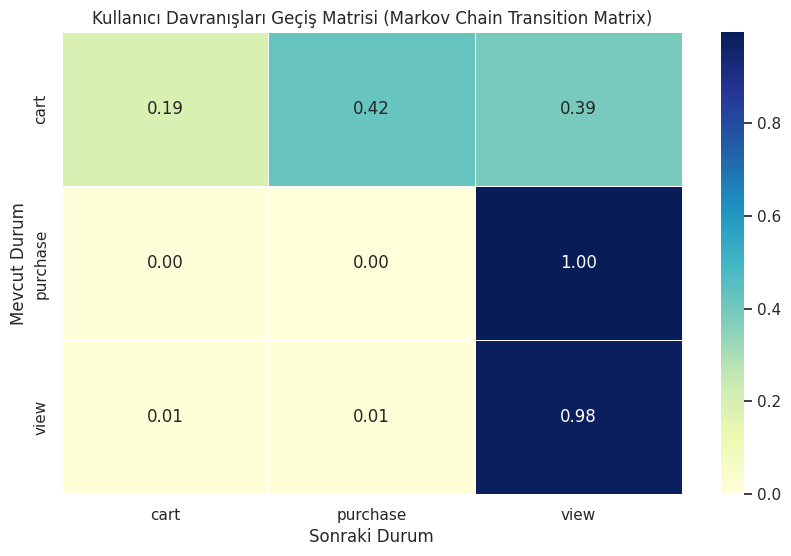

Matris değerleri başarıyla hesaplandı ve görsel kaydedildi.


In [3]:
# ---------------------------------------------------------
# BÖLÜM 3: MARKOV ZİNCİRİ VE GEÇİŞ MATRİSİ
# Amaç: Bir event'ten diğerine geçiş olasılığını bulmak.
# ---------------------------------------------------------

# Bir sonraki olayı (Next Event) sütun olarak ekle
df_train['next_event'] = df_train.groupby('session_id')['event_type'].shift(-1)

# Geçiş Matrisini (Crosstab) Oluştur
transition_matrix = pd.crosstab(df_train['event_type'], df_train['next_event'], normalize='index')

# GÖRSELLEŞTİRME: Isı Haritası (Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=.5)
plt.title('Kullanıcı Davranışları Geçiş Matrisi (Markov Chain Transition Matrix)')
plt.ylabel('Mevcut Durum')
plt.xlabel('Sonraki Durum')

# Resmi kaydet (Rapor için)
plt.savefig('grafik_gecis_matrisi.png', bbox_inches='tight')
plt.show()

print("Matris değerleri başarıyla hesaplandı ve görsel kaydedildi.")

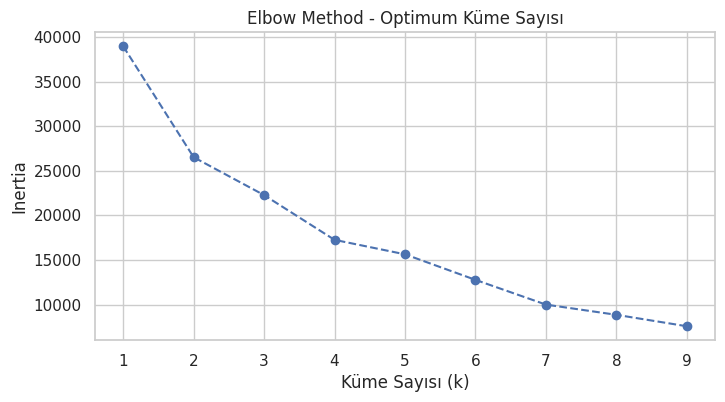


--- KÜME ORTALAMALARI (DAVRANIŞ PROFİLLERİ) ---
            duration  total_events  unique_products      cart  purchase  \
Cluster                                                                   
0        1070.513561     10.825897         6.727034  0.117235  0.134733   
1        1871.637097     34.008065        20.846774  0.056452  0.072581   
2         108.819904      2.459330         1.773780  0.019330  0.026029   

              view  
Cluster             
0        10.573928  
1        33.879032  
2         2.413971  


In [4]:
# ---------------------------------------------------------
# BÖLÜM 4: KULLANICI SEGMENTASYONU (K-MEANS & PCA)
# Amaç: Session bazlı özellikler çıkarıp benzer kullanıcıları gruplamak.
# ---------------------------------------------------------

# 4.1. Öznitelik Çıkarımı (Feature Extraction)
# Her session için özet istatistikler
session_features = df_train.groupby('session_id').agg({
    'time_diff': 'sum',           # Toplam Süre (Duration)
    'event_type': 'count',        # Toplam Tıklama (Total Events)
    'product_id': 'nunique'       # Gezilen Farklı Ürün Sayısı
}).rename(columns={'time_diff': 'duration', 'event_type': 'total_events', 'product_id': 'unique_products'})

# Sepet ve Satın Alma sayılarını ekle
event_counts = df_train.pivot_table(index='session_id', columns='event_type', aggfunc='size', fill_value=0)
session_features = session_features.join(event_counts)

# Eksik sütun kontrolü (Eğer veride purchase yoksa hata vermesin)
for col in ['view', 'cart', 'purchase']:
    if col not in session_features.columns:
        session_features[col] = 0

# 4.2. Ölçeklendirme (Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(session_features)

# 4.3. Elbow Method (En iyi küme sayısını bulmak için)
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Elbow Grafiği Çizimi
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method - Optimum Küme Sayısı')
plt.xlabel('Küme Sayısı (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.savefig('grafik_elbow_method.png') # Kaydet
plt.show()

# 4.4. Final Kümeleme (K=3 Seçildi)
k_final = 3
kmeans = KMeans(n_clusters=k_final, random_state=42)
session_features['Cluster'] = kmeans.fit_predict(X_scaled)

# Küme Ortalamalarını Göster (Rapor Tablosu İçin)
print("\n--- KÜME ORTALAMALARI (DAVRANIŞ PROFİLLERİ) ---")
print(session_features.groupby('Cluster').mean())

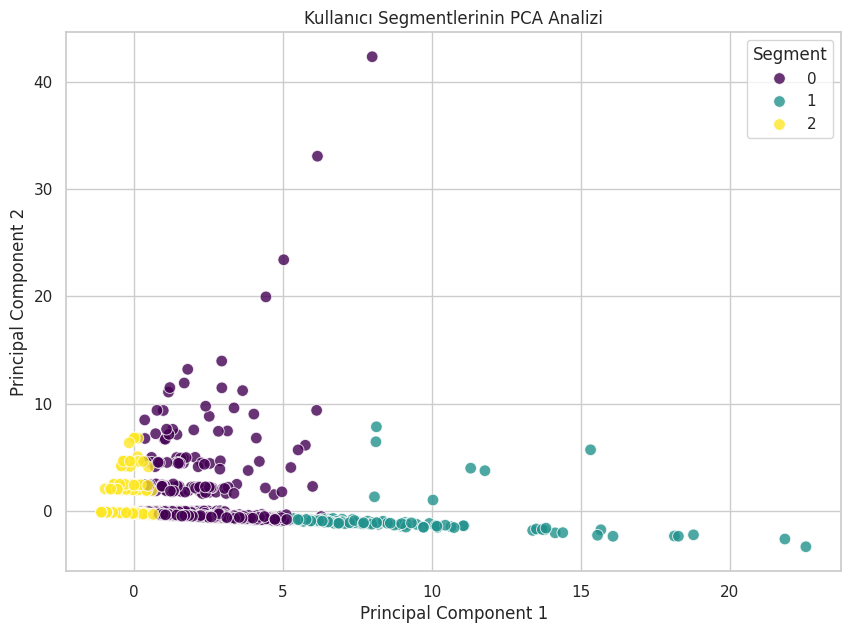

In [5]:
# ---------------------------------------------------------
# BÖLÜM 5: PCA İLE GÖRSELLEŞTİRME
# Amaç: Kümeleri 2 boyutlu düzlemde göstermek.
# ---------------------------------------------------------

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Görselleştirme DataFrame'i
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = session_features['Cluster'].values

# Scatter Plot Çizimi
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Cluster',
    palette='viridis',
    data=pca_df,
    s=70, alpha=0.8
)
plt.title('Kullanıcı Segmentlerinin PCA Analizi')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Segment')
plt.savefig('grafik_pca_kumeler.png', bbox_inches='tight')
plt.show()